In [30]:
import pandas as pd
import polars as pl

In [31]:
students   = pd.read_csv("students.csv")
hackathons = pd.read_csv("hackathons.csv")
projects   = pd.read_csv("projects.csv")
# Задание на развитие: считайте из папки все файлы, имеющию расширение csv, при условии что вы не знаете
# название файлов
from pathlib import Path

tables = {}
for f in Path(".").glob("*.csv"):
    tables[f.stem] = pd.read_csv(f)
    print(f.name, tables[f.stem].shape)
#print(tables.keys())

hackathons.csv (10, 5)
projects.csv (8, 5)
students.csv (10, 5)


In [32]:
# 2. Просмотр содержимого
for name, df in [("students", students), ("hackathons", hackathons), ("projects", projects)]:
    print(f"=== {name}: {df.shape[0]} строк, {df.shape[1]} столбцов ===")
    display(df.head())          # в обычном Python замените на print(df.head())
    print(df.dtypes, "\n")

# Вопросы студентам:
# - что означает одна строка в каждой таблице?
# - в какой таблице student_id уникален?
# в students одна строка = один студент, в hackathons = одно участие студента в хакатоне,
# в projects = один проект (студента ищем по фамилии и группе)
# student_id уникален в students, в hackathons может повторится тк один студент ходит на несколько хакатонов

=== students: 10 строк, 5 столбцов ===


,student_id,full_name,group,avg_grade,attendance_pct
0,101,Иванов Иван,ИС-101,4.5,92
1,102,Петрова Анна,ИС-101,4.8,97
2,103,Сидоров Олег,ИС-101,3.6,70
3,104,Кузнецова Мария,ИС-102,4.1,85
4,105,Смирнов Дмитрий,ИС-102,3.9,78


student_id          int64
full_name             str
group                 str
avg_grade         float64
attendance_pct      int64
dtype: object 

=== hackathons: 10 строк, 5 столбцов ===


,student_id,group,hackathon,place,prize_rub
0,101,ИС-101,AI-Transport,2,30000
1,101,ИС-101,DataFest,5,0
2,102,ИС-101,AI-Transport,1,50000
3,104,ИС-102,DataFest,3,15000
4,106,ИС-102,AI-Transport,4,0


student_id    int64
group           str
hackathon       str
place         int64
prize_rub     int64
dtype: object 

=== projects: 8 строк, 5 столбцов ===


,surname,group_name,case_name,status,score
0,иванов,ИС-101,Умный светофор,сдан,90
1,Петрова,ис-101,Прогноз ДТП,сдан,95
2,Иванов,ИС-102,Анализ пассажиропотока,в работе,60
3,Попова,ИС-102,Прогноз ДТП,сдан,98
4,Кузнецова,ИС-102,Анализ пассажиропотока,сдан,80


surname         str
group_name      str
case_name       str
status          str
score         int64
dtype: object 



In [33]:
# Вбейте сюда код для проверки уникальности student_id в students и hackathons
print("students:", students["student_id"].is_unique,len(students), students["student_id"].nunique())
print("hackathons:", hackathons["student_id"].is_unique, len(hackathons), hackathons["student_id"].nunique())
print(hackathons["student_id"].value_counts().head(3))

students: True 10 10
hackathons: False 10 7
student_id
106    3
101    2
102    1
Name: count, dtype: int64


# Изучаем особенности объединения датасетов


In [34]:
df_merge = students.merge(hackathons, on="student_id", how='left',
                              suffixes=("_stud", "_hack"))
df_merge[:5]

,student_id,full_name,group_stud,avg_grade,attendance_pct,group_hack,hackathon,place,prize_rub
0,101,Иванов Иван,ИС-101,4.5,92,ИС-101,AI-Transport,2.0,30000.0
1,101,Иванов Иван,ИС-101,4.5,92,ИС-101,DataFest,5.0,0.0
2,102,Петрова Анна,ИС-101,4.8,97,ИС-101,AI-Transport,1.0,50000.0
3,103,Сидоров Олег,ИС-101,3.6,70,NaN,NaN,NaN,NaN
4,104,Кузнецова Мария,ИС-102,4.1,85,ИС-102,DataFest,3.0,15000.0


In [35]:
df_merge = students.merge(hackathons, 
                          left_on=["student_id", "group"], #передаем список ключей из первого массива (список 1)
                          right_on=["student_id", "group"], #передаем список ключей из правого массива (в строгой логической последовательности списка 1)
                          how='left',
                              suffixes=("_stud", "_hack"))
df_merge[:5]

,student_id,full_name,group,avg_grade,attendance_pct,hackathon,place,prize_rub
0,101,Иванов Иван,ИС-101,4.5,92,AI-Transport,2.0,30000.0
1,101,Иванов Иван,ИС-101,4.5,92,DataFest,5.0,0.0
2,102,Петрова Анна,ИС-101,4.8,97,AI-Transport,1.0,50000.0
3,103,Сидоров Олег,ИС-101,3.6,70,NaN,NaN,NaN
4,104,Кузнецова Мария,ИС-102,4.1,85,DataFest,3.0,15000.0


In [36]:
# Задание. Проведите анализ различных способов объединения массивов: "inner", "left", "right", "outer"
# Оцените в чем разница полученных результатов, сделайте выводы. 
# Как приваильно объединять массивы? (и для какой задачи, дайте развернутый ответ на три предложения.
# Сначала поставьте бизнес-задачу, потом дайте ответ)
# Уровни сложности:
# start: пишите каждое объединение отдельное
# medium: в цикле
for m in ["inner", "left", "right", "outer"]:
    x = students.merge(hackathons, on="student_id", how=m, suffixes=("_stud", "_hack"))
    print(m, "строк:", len(x), "| студентов:", x["student_id"].nunique(), "| пропусков в ФИО:", x["full_name"].isna().sum())
    #print(x)

# inner - только те у кого id есть в обеих таблицах, студенты без хакатонов пропадают
# left - все студенты, у кого не было хакатонов NaN в hackathon/place, строк 13 а не 10 тк 101 ходил 2 раза а 106 три
# right - все записи хакатонов, у 111 и 112 нет ФИО, их нет в списке студентов
# outer - вообще все строки из обеих таблиц
# бизнес задача: деканат хочет по каждому студенту видеть средний балл и сколько он выиграл на хакатонах
# что бы выбрать кого премировать. тут нужен left от students, тк студенты без хакатонов тоже должны
# остаться в отчете (у них 0 побед), а inner их бы выкинул, outer полезен только что бы найти мусор вроде 111/112

inner строк: 8 | студентов: 5 | пропусков в ФИО: 0
left строк: 13 | студентов: 10 | пропусков в ФИО: 0
right строк: 10 | студентов: 7 | пропусков в ФИО: 2
outer строк: 15 | студентов: 12 | пропусков в ФИО: 2


In [37]:
# %% 3.3 Откуда пришла строка: indicator
chk = students.merge(hackathons, on="student_id", how="outer",
                     suffixes=("_stud", "_hack"), 
                     indicator=True # этот параметр в каком массиве есть запись по ключу
                     )
chk[:3]

,student_id,full_name,group_stud,avg_grade,attendance_pct,group_hack,hackathon,place,prize_rub,_merge
0,101,Иванов Иван,ИС-101,4.5,92.0,ИС-101,AI-Transport,2.0,30000.0,both
1,101,Иванов Иван,ИС-101,4.5,92.0,ИС-101,DataFest,5.0,0.0,both
2,102,Петрова Анна,ИС-101,4.8,97.0,ИС-101,AI-Transport,1.0,50000.0,both


In [38]:
chk['_merge'].value_counts()

_merge
both          8
left_only     5
right_only    2
Name: count, dtype: int64

In [39]:
# Собираем аналитику по данным:
print('Студенты, которые не учавствовали в хакатоне')
display(chk[chk["_merge"] == "left_only"][["student_id", "full_name"]])

Студенты, которые не учавствовали в хакатоне


,student_id,full_name
3,103,Сидоров Олег
5,105,Смирнов Дмитрий
9,107,Волков Артём
10,108,Морозова Ольга
12,110,Иванов Пётр


In [40]:
# Задание: выведите список студентов, участвующих в хакатоне, а также отдельно - их общее количество.
# Оцените, какая доля студентов учавствуте в хакатонах?
uch = chk[chk["_merge"]=="both"][["student_id","full_name"]].drop_duplicates()
print(uch)
print("участников:", len(uch))
print("доля:",len(uch)/len(students))
# половина студентов ходит на хакатоны, drop_duplicates нужен тк 101 и 106 были по несколько раз

    student_id        full_name
0          101      Иванов Иван
2          102     Петрова Анна
4          104  Кузнецова Мария
6          106     Попова Елена
11         109    Новиков Игорь
участников: 5
доля: 0.5


In [41]:
# join по индексу 
si = students.set_index("student_id") # у polars нет аналога set_index и в целом индекса
hi = hackathons.set_index("student_id")
display(si.join(hi, how="left", lsuffix="_stud", rsuffix="_hack").head())



,full_name,group_stud,avg_grade,attendance_pct,group_hack,hackathon,place,prize_rub
student_id,,,,,,,,
101,Иванов Иван,ИС-101,4.5,92,ИС-101,AI-Transport,2.0,30000.0
101,Иванов Иван,ИС-101,4.5,92,ИС-101,DataFest,5.0,0.0
102,Петрова Анна,ИС-101,4.8,97,ИС-101,AI-Transport,1.0,50000.0
103,Сидоров Олег,ИС-101,3.6,70,NaN,NaN,NaN,NaN
104,Кузнецова Мария,ИС-102,4.1,85,ИС-102,DataFest,3.0,15000.0


# Ошибки логики при объединении массивов
Студент с id=1 участвовал в двух хакатонах. Если вы думаете, что связь «один студент — один хакатон», и делаете merge без проверки, pandas молча продублирует строку, и вы получите 3 строки вместо ожидаемых 2. Это классический картезианский взрыв (cartesian explosion).

In [42]:
# защита от неожиданной модели данных
try:
    students.merge(hackathons, on="student_id", validate="1:1") # в polars есть этот гиперпараметр validate (при использовании join (вместо merge в pd))
except Exception as e:
    print('Ваша модель данных не соотвествует модели объединения')
    print(type(e).__name__, e)           # MergeError: правая таблица не уникальна



Ваша модель данных не соотвествует модели объединения
MergeError Merge keys are not unique in right dataset; not a one-to-one merge
Duplicates in right:
  student_id
        101
        106
        106 ...


In [43]:
# защита от неожиданной модели данных
try:
    merge_1 = students.merge(hackathons, on="student_id", validate="1:m")
    display(merge_1[:3])
except Exception as e:
    print('Ваша модель данных не соотвествует модели объединения')
    print(type(e).__name__, e)           # MergeError: правая таблица не уникальна



,student_id,full_name,group_x,avg_grade,attendance_pct,group_y,hackathon,place,prize_rub
0,101,Иванов Иван,ИС-101,4.5,92,ИС-101,AI-Transport,2,30000
1,101,Иванов Иван,ИС-101,4.5,92,ИС-101,DataFest,5,0
2,102,Петрова Анна,ИС-101,4.8,97,ИС-101,AI-Transport,1,50000


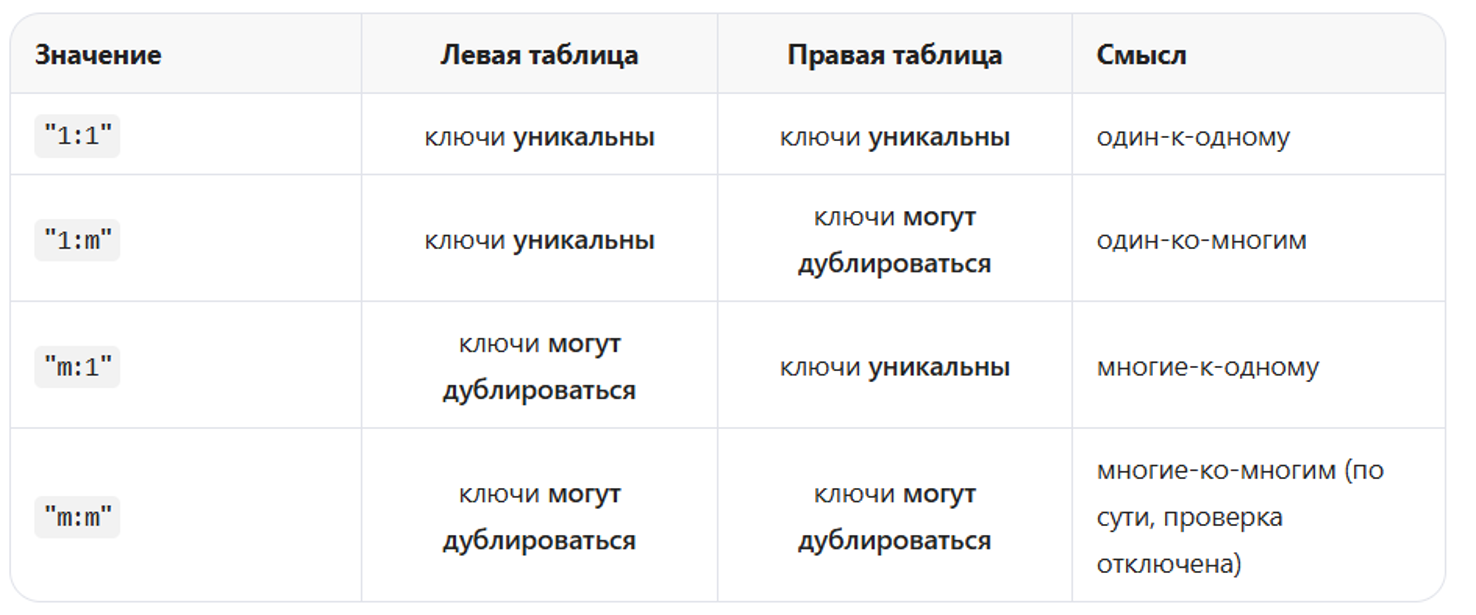

# Отступление. Новая команда - isin

In [44]:
# Изучим новую команду - isin (включение)
students[students["student_id"].isin(hackathons["student_id"])]

,student_id,full_name,group,avg_grade,attendance_pct
0,101,Иванов Иван,ИС-101,4.5,92
1,102,Петрова Анна,ИС-101,4.8,97
3,104,Кузнецова Мария,ИС-102,4.1,85
5,106,Попова Елена,ИС-102,4.9,99
8,109,Новиков Игорь,ИС-103,4.0,81


In [45]:
# Изучим новую команду - isin (проверяет вхождению в коллекцию (набор) значений)
# для polars аналог is_in
students[students["group"].isin(['ИС-103'])]

,student_id,full_name,group,avg_grade,attendance_pct
6,107,Волков Артём,ИС-103,3.2,60
7,108,Морозова Ольга,ИС-103,4.3,88
8,109,Новиков Игорь,ИС-103,4.0,81


In [46]:
# Изучим новую команду - isin (проверяет вхождению в коллекцию (набор) значений)
# Он не ищет подстроку: так писать не правильно
students[students["group"].isin(["ИС-103"])]
# со строкой 'ИС-103' была ошибка only list-like objects are allowed, isin нужен список

,student_id,full_name,group,avg_grade,attendance_pct
6,107,Волков Артём,ИС-103,3.2,60
7,108,Морозова Ольга,ИС-103,4.3,88
8,109,Новиков Игорь,ИС-103,4.0,81


In [47]:
semi = students[students["student_id"].isin(hackathons["student_id"])]    # 5 студентов
anti = students[~students["student_id"].isin(hackathons["student_id"])]   # 5 студентов
print('количество студентов, которых ходят на хакатон: ', len(semi))
print('количество студентов, которых НЕ ходят на хакатон: ', len(anti))

количество студентов, которых ходят на хакатон:  5
количество студентов, которых НЕ ходят на хакатон:  5


# Формирование комбинаций. cross
1. Генерация полного каталога (Все возможные комбинации)
Это самая частая причина использования cross. Когда вам нужно создать справочник всех возможных вариантов чего-либо.
Пример: У вас есть список цветов и список размеров. Вам нужно создать таблицу всех возможных артикулов (SKU), чтобы потом заполнить её остатками на складе.
```
colors = pd.DataFrame({'color': ['Красный', 'Синий']})
sizes = pd.DataFrame({'size': ['S', 'M', 'L']})
# Создаем все комбинации
skus = colors.merge(sizes, how='cross') 
```
2. Создание "временной сетки" (Calendar Grid)
В аналитике временных рядов часто бывает проблема: в таблице продаж есть только те дни, когда продажи были. Но для построения красивых графиков или расчета скользящих средних нужна таблица, где есть каждый день для каждого объекта.
Пример: У вас есть список магазинов и список дат.

3. Попарное сравнение "Всё со всем" (Pairwise comparison)
Иногда нужно сравнить каждый объект с каждым другим объектом.
Пример: У вас есть таблица городов с координатами (широта, долгота). Вам нужно посчитать расстояние между каждой парой городов.

In [48]:
# cross и аналоги semi / anti
print(len(students.merge(hackathons, how="cross")))           # 
# how="cross" - это операция, которая создаёт декартово произведение двух DataFrame. 
# Это значит, что каждая строка из первого DataFrame соединяется со каждой строкой из второго DataFrame. 
# При этом сохраняется порядок строк первого DataFrame.
# ВАЖНО!
# Ключи здесь не используются и не имеют смысла.
students.merge(hackathons, how="cross")[:6]


100


,student_id_x,full_name,group_x,avg_grade,attendance_pct,student_id_y,group_y,hackathon,place,prize_rub
0,101,Иванов Иван,ИС-101,4.5,92,101,ИС-101,AI-Transport,2,30000
1,101,Иванов Иван,ИС-101,4.5,92,101,ИС-101,DataFest,5,0
2,101,Иванов Иван,ИС-101,4.5,92,102,ИС-101,AI-Transport,1,50000
3,101,Иванов Иван,ИС-101,4.5,92,104,ИС-102,DataFest,3,15000
4,101,Иванов Иван,ИС-101,4.5,92,106,ИС-102,AI-Transport,4,0
5,101,Иванов Иван,ИС-101,4.5,92,106,ИС-102,CityHack,1,60000


# Добавляем третью таблицу

In [49]:
# 4.1 Третий датасет: ключа id нет, есть фамилия и группа
display(projects)
# Проблемы: регистр, пробелы; в students ФИО одной строкой; фамилия «Иванов» в двух группах


,surname,group_name,case_name,status,score
0,иванов,ИС-101,Умный светофор,сдан,90
1,Петрова,ис-101,Прогноз ДТП,сдан,95
2,Иванов,ИС-102,Анализ пассажиропотока,в работе,60
3,Попова,ИС-102,Прогноз ДТП,сдан,98
4,Кузнецова,ИС-102,Анализ пассажиропотока,сдан,80
5,Волков,ИС-103,Карта аварийных участков,сдан,72
6,МОРОЗОВА,ИС-103,Умный светофор,сдан,85
7,Белов,ИС-101,Прогноз ДТП,сдан,70


In [50]:
students[:2]

,student_id,full_name,group,avg_grade,attendance_pct
0,101,Иванов Иван,ИС-101,4.5,92
1,102,Петрова Анна,ИС-101,4.8,97


In [51]:
# Приводим к нижней строке
students["full_name"].str.lower()

0        иванов иван
1       петрова анна
2       сидоров олег
3    кузнецова мария
4    смирнов дмитрий
5       попова елена
6       волков артём
7     морозова ольга
8      новиков игорь
9        иванов пётр
Name: full_name, dtype: str

In [52]:
# Выделим новый столбец с фамилией на основе столбцы full_name (используем assign)
students.assign(surname=students["full_name"].str.split().str[0])
# Метод assign() в библиотеке Pandas позволяет создавать новые столбцы в DataFrame, 
# не изменяя при этом исходный объект — он возвращает новый DataFrame с добавленными данными

,student_id,full_name,group,avg_grade,attendance_pct,surname
0,101,Иванов Иван,ИС-101,4.5,92,Иванов
1,102,Петрова Анна,ИС-101,4.8,97,Петрова
2,103,Сидоров Олег,ИС-101,3.6,70,Сидоров
3,104,Кузнецова Мария,ИС-102,4.1,85,Кузнецова
4,105,Смирнов Дмитрий,ИС-102,3.9,78,Смирнов
5,106,Попова Елена,ИС-102,4.9,99,Попова
6,107,Волков Артём,ИС-103,3.2,60,Волков
7,108,Морозова Ольга,ИС-103,4.3,88,Морозова
8,109,Новиков Игорь,ИС-103,4.0,81,Новиков
9,110,Иванов Пётр,ИС-102,3.8,74,Иванов


In [53]:
# Тоже самое, с приведением к нижнему регистрку
pars_student = students.assign(surname=students["full_name"].str.lower().str.split().str[0])
pars_student

,student_id,full_name,group,avg_grade,attendance_pct,surname
0,101,Иванов Иван,ИС-101,4.5,92,иванов
1,102,Петрова Анна,ИС-101,4.8,97,петрова
2,103,Сидоров Олег,ИС-101,3.6,70,сидоров
3,104,Кузнецова Мария,ИС-102,4.1,85,кузнецова
4,105,Смирнов Дмитрий,ИС-102,3.9,78,смирнов
5,106,Попова Елена,ИС-102,4.9,99,попова
6,107,Волков Артём,ИС-103,3.2,60,волков
7,108,Морозова Ольга,ИС-103,4.3,88,морозова
8,109,Новиков Игорь,ИС-103,4.0,81,новиков
9,110,Иванов Пётр,ИС-102,3.8,74,иванов


In [54]:
# Поимщем всех ивановых
pars_student[pars_student['surname'].str.find('иванов')!= - 1]

,student_id,full_name,group,avg_grade,attendance_pct,surname
0,101,Иванов Иван,ИС-101,4.5,92,иванов
9,110,Иванов Пётр,ИС-102,3.8,74,иванов


In [55]:
# Почему одной фамилии мало
projects['surname'] = projects['surname'].str.lower()
bad = pars_student.merge(projects, on="surname", how="inner")
bad
# print(len(bad))   # без очистки Иванов(101) и Иванов(110) пересекаются неверно, регистр теряет совпадения


,student_id,full_name,group,avg_grade,attendance_pct,surname,group_name,case_name,status,score
0,101,Иванов Иван,ИС-101,4.5,92,иванов,ИС-102,Анализ пассажиропотока,в работе,60
1,102,Петрова Анна,ИС-101,4.8,97,петрова,ис-101,Прогноз ДТП,сдан,95
2,104,Кузнецова Мария,ИС-102,4.1,85,кузнецова,ИС-102,Анализ пассажиропотока,сдан,80
3,106,Попова Елена,ИС-102,4.9,99,попова,ИС-102,Прогноз ДТП,сдан,98
4,107,Волков Артём,ИС-103,3.2,60,волков,ИС-103,Карта аварийных участков,сдан,72
5,108,Морозова Ольга,ИС-103,4.3,88,морозова,ИС-103,Умный светофор,сдан,85
6,110,Иванов Пётр,ИС-102,3.8,74,иванов,ИС-102,Анализ пассажиропотока,в работе,60


In [56]:
# Команды для удаления пробеллов в начале и конце строки - strip и поднимаем в верхний регистра - upper
students["group"].str.strip().str.upper()

0    ИС-101
1    ИС-101
2    ИС-101
3    ИС-102
4    ИС-102
5    ИС-102
6    ИС-103
7    ИС-103
8    ИС-103
9    ИС-102
Name: group, dtype: str

In [57]:
# Формируем ключ
students["surname_key"] = students["full_name"].str.split().str[0].str.strip().str.lower()
students["group_key"]   = students["group"].str.strip().str.upper()

projects["surname_key"] = projects["surname"].str.strip().str.lower()
projects["group_key"]   = projects["group_name"].str.strip().str.upper()

# Задание: посмотрите результаты, являются ли ключи уникальными для этих массивов?
# Важно для определения модели объединения validate
print("students:", students.duplicated(["surname_key", "group_key"]).sum(), "дублей ключа")
print("projects:", projects.duplicated(["surname_key", "group_key"]).sum(), "дублей ключа")
print("одна фамилия в students уникальна?", students["surname_key"].is_unique)
# по одной фамилии не уникально (ивановы), а фамилия+группа уникальны в обеих, значит можно validate="1:1"

students: 0 дублей ключа
projects: 0 дублей ключа
одна фамилия в students уникальна? False


In [58]:
# Объединение по составному ключу
sp = students.merge(projects, on=["surname_key", "group_key"], how="outer",
                    indicator=True, validate="1:1")
print(sp["_merge"].value_counts())
display(sp[sp["_merge"] != "both"][["full_name", "surname", "_merge"]])

# 4.5 Итоговая таблица: все студенты, проекты по возможности
final = students.merge(
    projects[["surname_key", "group_key", "case_name", "status", "score"]],
    on=["surname_key", "group_key"], how="left", validate="1:1")
final = final.merge(
    hackathons.drop(columns="group"), on="student_id", how="left", validate="1:m")
print(len(final))   # 13: из-за хакатонов студентов 101 и 106 строк стало больше (fan-out)
display(final)

_merge
both          7
left_only     3
right_only    1
Name: count, dtype: int64


,full_name,surname,_merge
0,NaN,белов,right_only
6,Новиков Игорь,NaN,left_only
9,Сидоров Олег,NaN,left_only
10,Смирнов Дмитрий,NaN,left_only


13


,student_id,full_name,group,avg_grade,attendance_pct,surname_key,group_key,case_name,status,score,hackathon,place,prize_rub
0,101,Иванов Иван,ИС-101,4.5,92,иванов,ИС-101,Умный светофор,сдан,90.0,AI-Transport,2.0,30000.0
1,101,Иванов Иван,ИС-101,4.5,92,иванов,ИС-101,Умный светофор,сдан,90.0,DataFest,5.0,0.0
2,102,Петрова Анна,ИС-101,4.8,97,петрова,ИС-101,Прогноз ДТП,сдан,95.0,AI-Transport,1.0,50000.0
3,103,Сидоров Олег,ИС-101,3.6,70,сидоров,ИС-101,NaN,NaN,NaN,NaN,NaN,NaN
4,104,Кузнецова Мария,ИС-102,4.1,85,кузнецова,ИС-102,Анализ пассажиропотока,сдан,80.0,DataFest,3.0,15000.0
5,105,Смирнов Дмитрий,ИС-102,3.9,78,смирнов,ИС-102,NaN,NaN,NaN,NaN,NaN,NaN
6,106,Попова Елена,ИС-102,4.9,99,попова,ИС-102,Прогноз ДТП,сдан,98.0,AI-Transport,4.0,0.0
7,106,Попова Елена,ИС-102,4.9,99,попова,ИС-102,Прогноз ДТП,сдан,98.0,CityHack,1.0,60000.0
8,106,Попова Елена,ИС-102,4.9,99,попова,ИС-102,Прогноз ДТП,сдан,98.0,DataFest,2.0,30000.0
9,107,Волков Артём,ИС-103,3.2,60,волков,ИС-103,Карта аварийных участков,сдан,72.0,NaN,NaN,NaN
